In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
import matplotlib.image as mpimg

from scipy.interpolate import PchipInterpolator

import os

In [2]:
# cleaned file
f_path = os.path.join(
    "..", "data", "clean",
    "launches_clean_plotting.csv"
)

data = pd.read_csv(f_path)

data.tail(1)

,Date,total_payloads,Overall,USA,Europe,Asia,Other
37,2025-12-24,1,434,233,139,41,21


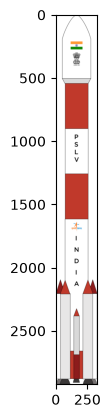

In [18]:
# load PSLV image
rocket_img = mpimg.imread(
    os.path.join(
        "..", "data", "image",
        "pslv.png"
    )
)

plt.imshow(rocket_img)

In [3]:
df = data.copy()

region_cols = ["USA", "Europe", "Asia", "Other"]

df_yearly = (
    df.assign(Date=pd.to_datetime(df["Date"]))
    .sort_values("Date")
    .set_index("Date")
    .resample("YE")[region_cols]
    .last()
    .ffill()
)

df_yearly["Overall"] = df_yearly[region_cols].sum(axis=1)

df_yearly["Year"] = df_yearly.index.year

df_yearly = df_yearly.reset_index(drop=True)

In [4]:
df_yearly

,USA,Europe,Asia,Other,Overall,Year
0,0.0,1.0,1.0,0.0,2.0,1999
1,0.0,1.0,1.0,0.0,2.0,2000
2,0.0,3.0,1.0,0.0,4.0,2001
3,0.0,3.0,1.0,0.0,4.0,2002
4,0.0,3.0,1.0,0.0,4.0,2003
5,0.0,3.0,1.0,0.0,4.0,2004
6,0.0,3.0,1.0,0.0,4.0,2005
7,0.0,3.0,1.0,0.0,4.0,2006
8,0.0,4.0,2.0,1.0,7.0,2007
9,0.0,8.0,5.0,3.0,16.0,2008


In [5]:
# regions to show
region_cols = ["USA", "Europe", "Asia", "Other"]

# dataset for plotting
df_plot = df_yearly.sort_values("Year").copy()

# actual non-smoothed data
x = df_plot["Year"].to_numpy(dtype=float)

y_usa = df_plot["USA"].to_numpy(dtype=float)
y_eu = df_plot["Europe"].to_numpy(dtype=float)
y_asia = df_plot["Asia"].to_numpy(dtype=float)
y_other = df_plot["Other"].to_numpy(dtype=float)

# smoothed data
x_sm = np.linspace(
    x.min(),
    x.max(),
    500
)

y_usa_sm = PchipInterpolator(x, y_usa)(x_sm)
y_eu_sm = PchipInterpolator(x, y_eu)(x_sm)
y_asia_sm = PchipInterpolator(x, y_asia)(x_sm)
y_other_sm = PchipInterpolator(x, y_other)(x_sm)

In [6]:
# milestones to annotate
y_min_milestone = 2010
df_mile = df_plot[df_plot["Year"]>=y_min_milestone]

milestone_years = list(range(y_min_milestone, 2026, 5))

milestone_totals = [
    df_mile[df_mile["Year"]==y]["Overall"].values[0] for y in milestone_years
]

In [7]:
# colors
# 00496FFF, #0F85A0FF, #EDD746FF, #ED8B00FF, #DD4124FF
#FCDD23FF, #F8B100FF, #CA697CFF, #AB74CFFF, #48439BFF, #03045e
"#042a2b","#5eb1bf","#cdedf6","#ef7b45","#d84727"
#4B6892FF, #F9E583FF, #FED43FFF, #F6BD28FF, #BE4C46FF
#2E0F16FF, #A32A2FFF, #EB9352FF, #F8E3DBFF, #91837DFF, #37947EFF
#4A3A3BFF, #984136FF, #C26A7AFF, #ECC0A1FF, #F0F0E4FF
#242424FF, #37253DFF, #852851FF, #E10131FF, #F6F4F5FF
#010101FF, #BA0C2FFF, #E03C31FF, #FFCD00FF

region_colors = [
    "#010101FF",   # USA
    "#BA0C2FFF",   # Europe
    "#E03C31FF",   # Asia
    "#FFCD00FF"    # Other
]

#F0F0E4FF, #ffffff
fc = "#ffffff"

# regions to plot
region_cols = ["USA", "Europe", "Asia", "Other"]

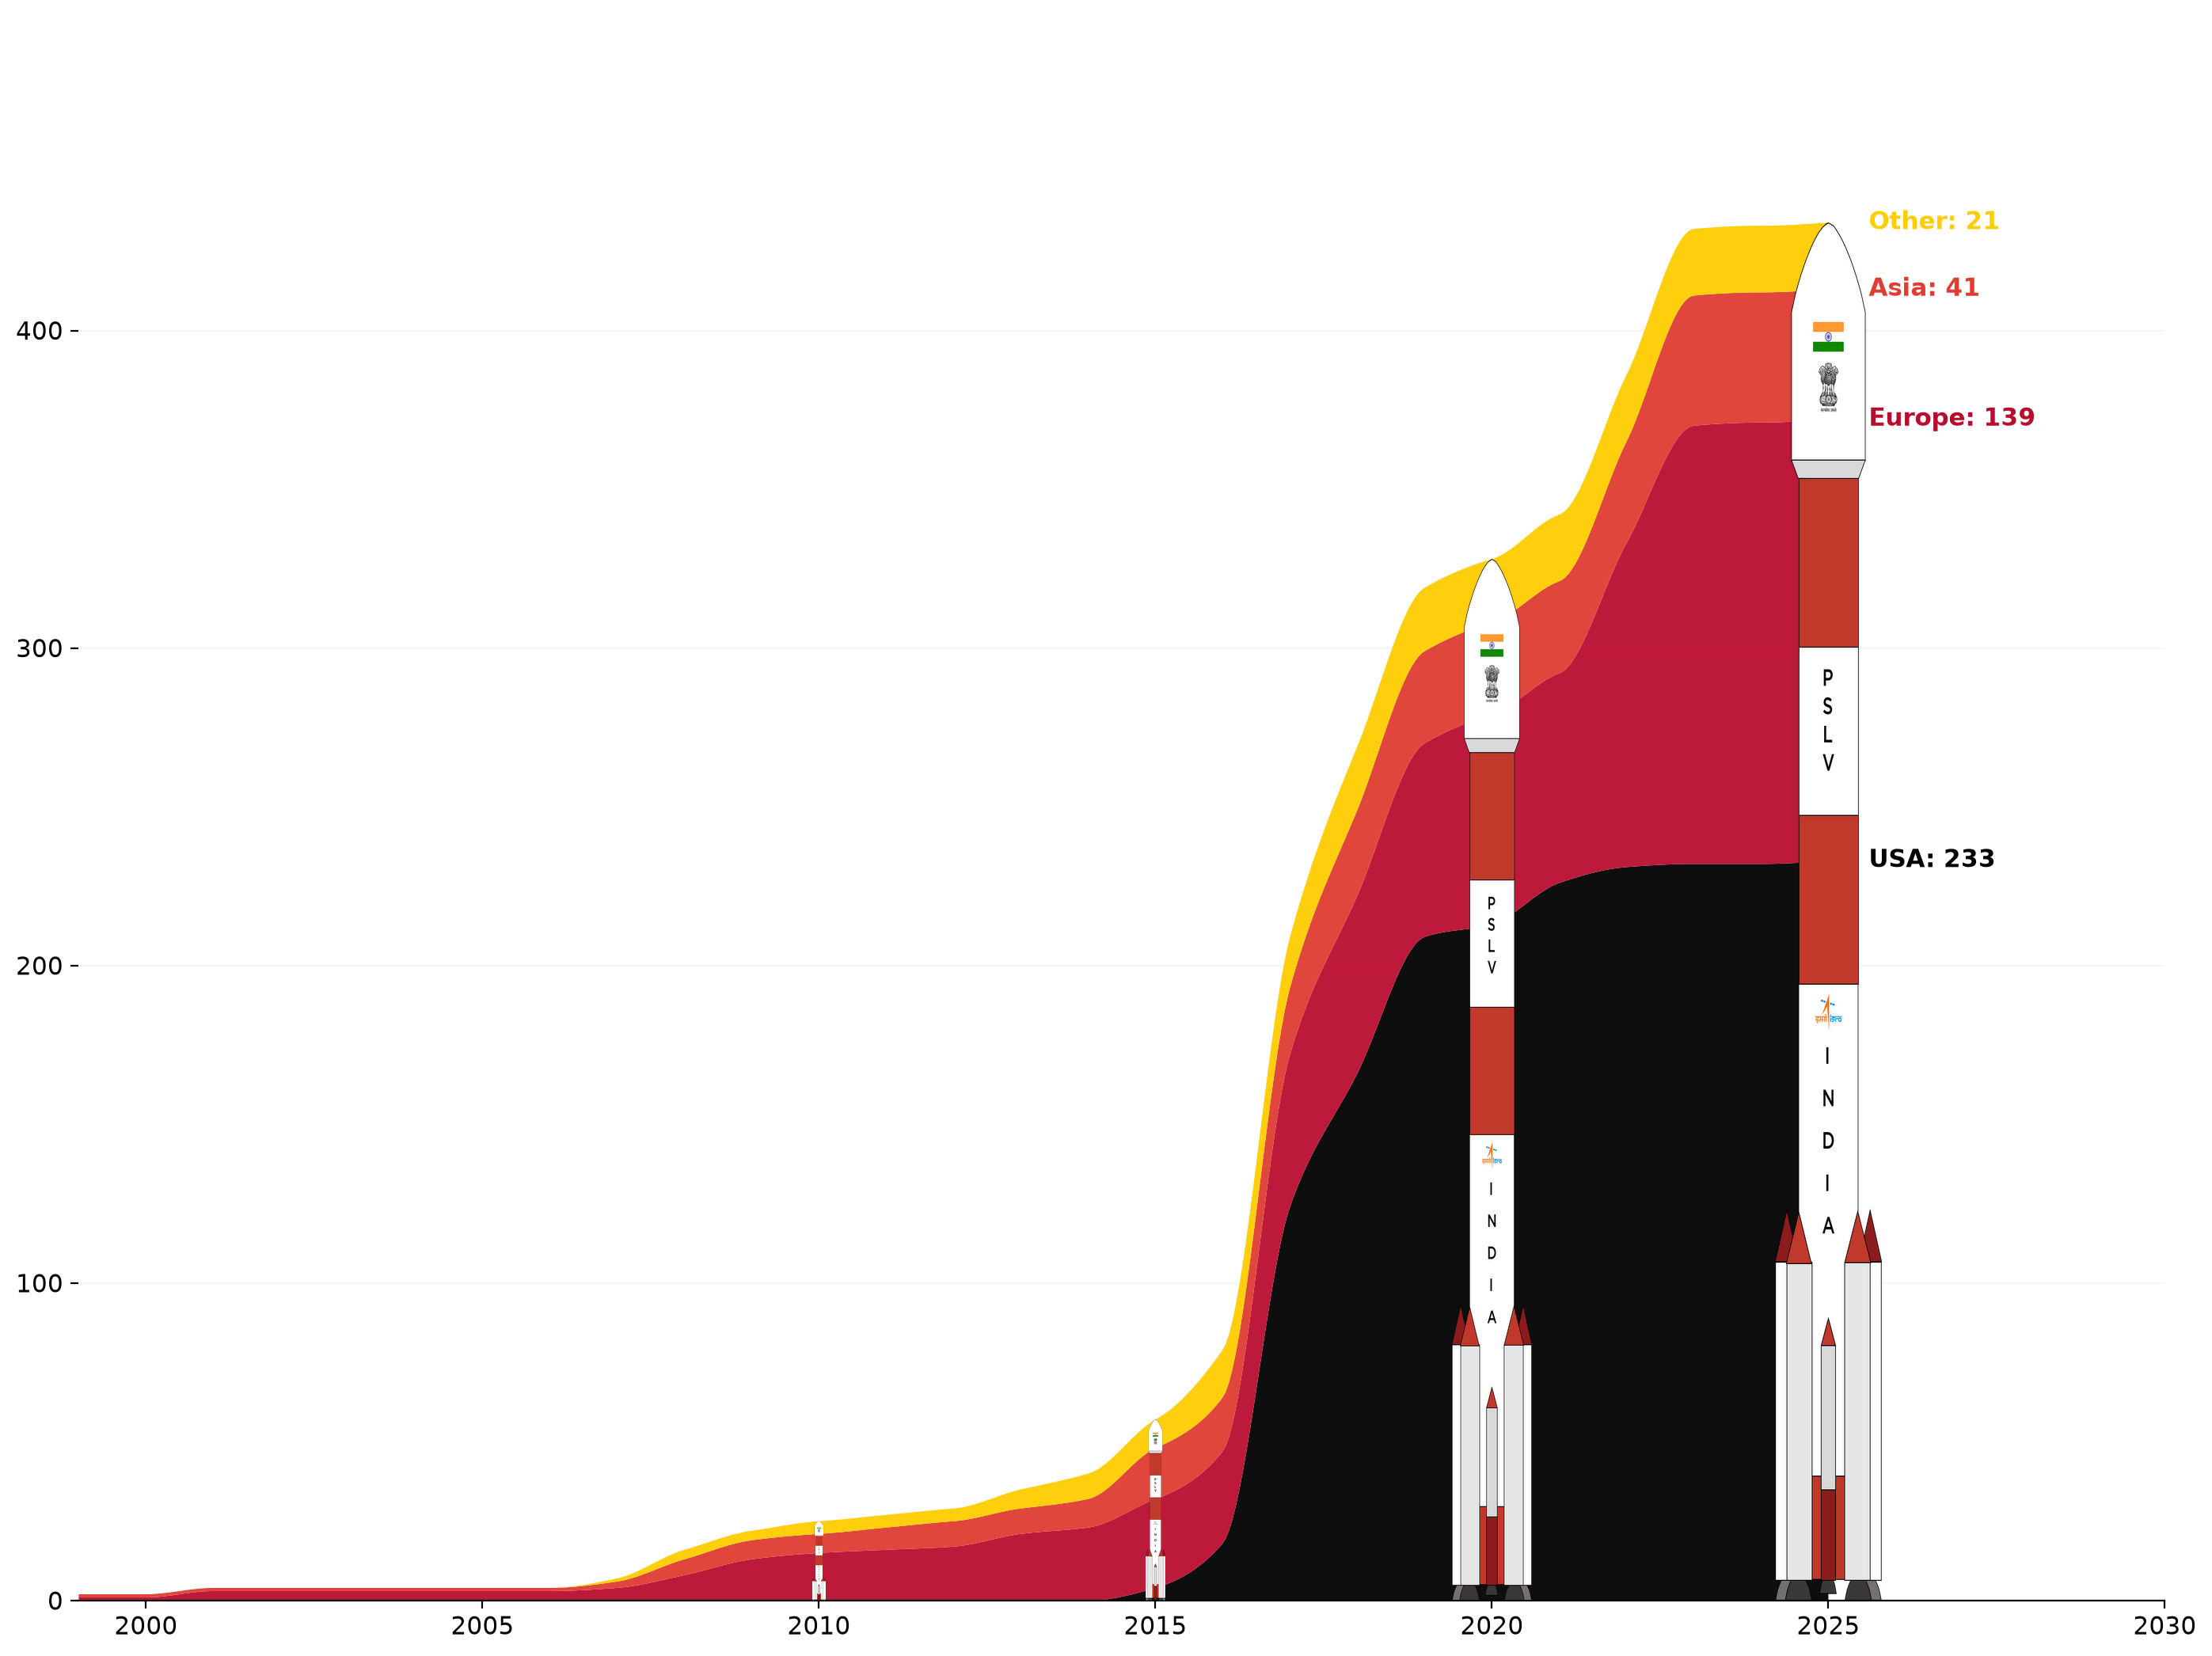

In [24]:
dpi = 200

fig, ax = plt.subplots(figsize=(17, 13), dpi=dpi)

fig.set_facecolor(fc)
ax.set_facecolor(fc)

ax.stackplot(
    x_sm,
    y_usa_sm,
    y_eu_sm,
    y_asia_sm,
    y_other_sm,
    labels=region_cols,
    colors=region_colors,
    alpha=0.95
)

final_values = np.array([
    y_usa[-1],
    y_eu[-1],
    y_asia[-1],
    y_other[-1]
])

cumulative_values = np.cumsum(final_values)

bottom_values = np.concatenate((
    [0],
    cumulative_values[:-1]
))

end_values = np.cumsum(final_values)

for region, color, end, value in zip(
    region_cols,
    region_colors,
    end_values,
    final_values
):

    ax.text(
        x.max() + 0.6,
        end,
        f"{region}: {int(value):,}",
        fontsize=11,
        fontweight="bold",
        color=color,
        va="center"
    )


overall_total = int(final_values.sum())

ax.xaxis.set_major_locator(
    MultipleLocator(5)
)

ax.set_xlim(
    x.min(),
    x.max() + 5
)

ax.set_ylim(
    0,
    overall_total * 1.15
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(
    axis="y",
    alpha=0.12
)

ax.set_axisbelow(True)

ax.tick_params(
    axis="both",
    labelsize=11
)


##################################################
# PSLV images annotation                         #
##################################################

# Width of rocket in x-axis units (years)
rocket_width = {
    2010:0.2,
    2015:0.3,
    2020:1.2,
    2025:1.6
}

# Preserve existing axis limits
x_limits = ax.get_xlim()
y_limits = ax.get_ylim()

# Draw rockets at milestone years
for year, total in zip(milestone_years, milestone_totals):

    ax.imshow(
        rocket_img,
        extent=[
            year - rocket_width.get(year, 2) / 2,
            year + rocket_width.get(year, 2) / 2,
            0,
            total
        ],
        aspect="auto",
        interpolation="lanczos",
        zorder=4
    )

# Restore axis limits
ax.set_xlim(x_limits)
ax.set_ylim(y_limits)


save_path = os.path.join(
    "..", "viz",
    "test_sm_pslv.jpeg"
)

plt.savefig(save_path, dpi=dpi, bbox_inches="tight", pad_inches=1)